1. Charger les données iris.

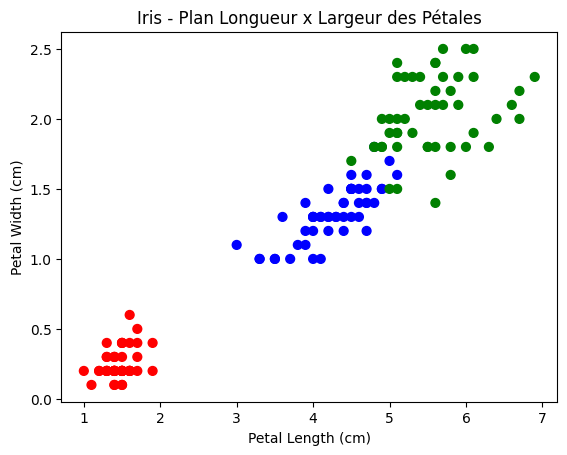

In [1]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

iris_data = load_iris()
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df['Species'] = iris_data.target

colorMap = np.array(["red", "blue", "green"])
plt.scatter(df["petal length (cm)"], df["petal width (cm)"],
            c=colorMap[df["Species"]], s=40)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris - Plan Longueur x Largeur des Pétales")
plt.show()

2. Créer deux variables X et Y, avec X constitues les vecteurs représentatifs des instances
d’iris et Y constitues les classes des iris.  

In [2]:
x = df[["sepal length (cm)", "sepal width (cm)",
        "petal length (cm)", "petal width (cm)"]]
y = df["Species"]

print(x)
print(y)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  5.1               3.5                1.4               0.2
1                  4.9               3.0                1.4               0.2
2                  4.7               3.2                1.3               0.2
3                  4.6               3.1                1.5               0.2
4                  5.0               3.6                1.4               0.2
..                 ...               ...                ...               ...
145                6.7               3.0                5.2               2.3
146                6.3               2.5                5.0               1.9
147                6.5               3.0                5.2               2.0
148                6.2               3.4                5.4               2.3
149                5.9               3.0                5.1               1.8

[150 rows x 4 columns]
0      0
1      0
2      0
3      0
4   

3. Avant de construire le modèle, séparer le jeu de données en deux : 70% pour
l’apprentissage, 30% pour le test. U

In [5]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)
print("Shape of x_train:", x_train.shape)
print("Shape of x_test:", x_test.shape)

Shape of x_train: (105, 4)
Shape of x_test: (45, 4)
Shape of y_train: (105,)
Shape of y_test: (45,)


4. Construire un modèle d’arbre de décision sur les données d’apprentissage et adopter
ce modèle aux données d’entraînement.

In [63]:
from sklearn import tree
clf = tree.DecisionTreeClassifier(criterion="gini")
clf.fit(x_train, y_train)

DecisionTreeClassifier()

In [74]:
from sklearn import tree
clf = tree.DecisionTreeClassifier(criterion="entropy")
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy')

5. Une fois l’apprentissage terminé, vous pouvez visualiser l’arbre avec matplotlib en
passant par la méthode « plot_tree » et afficher le nombre de niveaux possède
l’arbre «clf.get_depth()» . D’après l’arbre obtenu, quelles variables sont les plus
importantes ?

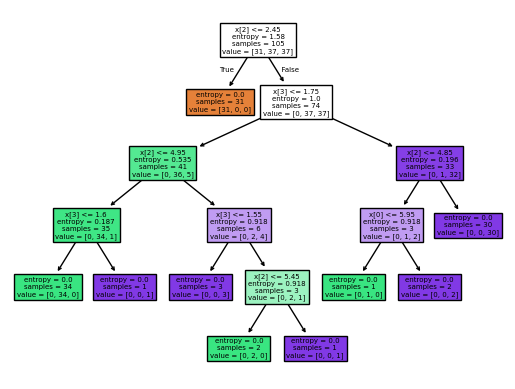

In [75]:
tree.plot_tree(clf,filled=True)
plt.show()

In [76]:
print(clf.get_depth())

5


6. Utiliser le modèle construit pour la prédiction sur les données de test

In [77]:
y_pred= clf.predict(x_test)
print(len(y_pred))

45


7. Calculer le score en test. D’après ce score, est ce que le modèle est performant ? et
peut-on faire confiance à ce score seul ?

In [78]:
clf.score(x_test, y_test)

1.0

8. Affichez le rapport de classification et la matrice de confiance en utilisant les fonctions
issues
package
« from
sklearn
import
metrics »
« classification_report(y_test,y_pred) », « metrics.confusion_matrix(y_test,y_pred) »

In [79]:
from sklearn import metrics
print(metrics.classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [80]:
print(metrics.confusion_matrix(y_test,y_pred))

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


9. Changez les valeurs de paramètres « max_depth » en les variant dans (1, 2, 3, 4, 5, 6, 7) et afficher les scores de train et de test obtenus avec ces différentes profondeurs.

<function matplotlib.pyplot.show(close=None, block=None)>

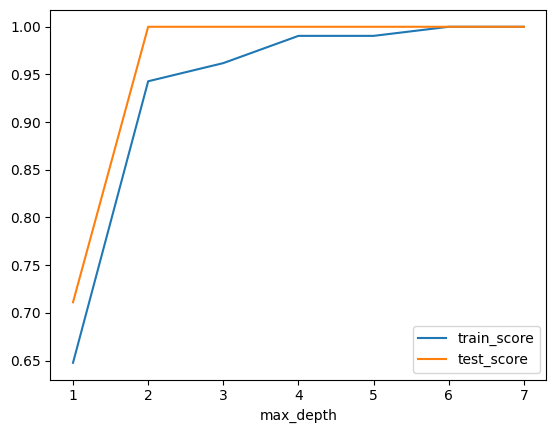

In [83]:
max_deph=range(1,8)
train_score=[]
test_score=[]
for d in max_deph:
  clf=tree.DecisionTreeClassifier(criterion="gini",max_depth=d)
  clf.fit(x_train,y_train)
  train_score.append(clf.score(x_train,y_train))
  test_score.append(clf.score(x_test,y_test))


plot_data=pd.DataFrame({"max_depth":max_deph,"train_score":train_score,"test_score":test_score})
plot_data.plot(x="max_depth",y=["train_score","test_score"])
plt.show

ou apparit le sur apprentissage : tanque le trani score contune mais le test acercy deminue ou stagle . ua arbre plus prufond plus des regle il peut mimoriser les donner dentrenement

qelle profonder somle optimale reponse : selle ou test score est maximale et lecart traain/test est trais fable